# Round 3 — Data Exploration
Raw graphs only. No strategies, no signals, no optimization.

**Train**: days 0, 1 + first half of day 2 (up to ts 499900)
**Val** (hidden from all graphs): second half of day 2 (ts 500000–999900)


In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import math, warnings
warnings.filterwarnings('ignore')
%matplotlib inline
plt.rcParams['figure.figsize'] = (14, 4)
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.35


In [15]:
DATA_DIR = "ROUND_3"
DAYS     = [0, 1, 2]
DAY_COLORS = {0: 'steelblue', 1: 'darkorange', 2: 'crimson'}

# ── Train/val split ───────────────────────────────────────────────────────────
# Everything with (day, timestamp) <= TRAIN_END is used for exploration.
# The second half of day 2 is held out and never plotted.
TRAIN_END = (2, 499900)

def load_prices(day):
    df = pd.read_csv(f"{DATA_DIR}/prices_round_3_day_{day}.csv", sep=";")
    df['day'] = day
    num = [c for c in df.columns if 'price' in c or 'volume' in c
           or c in ('mid_price', 'profit_and_loss')]
    for c in num: df[c] = pd.to_numeric(df[c], errors='coerce')
    return df

def load_trades(day):
    df = pd.read_csv(f"{DATA_DIR}/trades_round_3_day_{day}.csv", sep=";")
    df['day'] = day
    df['price']    = pd.to_numeric(df['price'],    errors='coerce')
    df['quantity'] = pd.to_numeric(df['quantity'], errors='coerce')
    return df

prices_all = pd.concat([load_prices(d) for d in DAYS], ignore_index=True)
trades_all = pd.concat([load_trades(d) for d in DAYS], ignore_index=True)

def _train_mask(df):
    return [(d, t) <= TRAIN_END for d, t in zip(df['day'], df['timestamp'])]

prices = prices_all[_train_mask(prices_all)].copy().reset_index(drop=True)
trades = trades_all[_train_mask(trades_all)].copy().reset_index(drop=True)

# Continuous tick index per product (for x-axis)
prices = prices.sort_values(['product','day','timestamp']).reset_index(drop=True)
prices['gx'] = prices.groupby('product').cumcount()

UNDERLYING = "VELVETFRUIT_EXTRACT"
HYDROGEL   = "HYDROGEL_PACK"
STRIKES    = [4000, 4500, 5000, 5100, 5200, 5300, 5400, 5500, 6000, 6500]

# S_idx used throughout for joining underlying price onto option rows
S_idx = prices[prices['product'] == UNDERLYING].set_index(['day','timestamp'])['mid_price']

train_days  = sorted(prices['day'].unique())
val_rows    = len(prices_all) - len(prices)
print(f"Train rows : {len(prices):,}  (days {train_days}, up to ts {TRAIN_END[1]} on day {TRAIN_END[0]})")
print(f"Val rows   : {val_rows:,}  (hidden)")
print(f"Trade rows : {len(trades):,}")
print(f"Products   : {sorted(prices['product'].unique())}")


Train rows : 300,000  (days [0, 1, 2], up to ts 499900 on day 2)
Val rows   : 60,000  (hidden)
Trade rows : 3,400
Products   : ['HYDROGEL_PACK', 'VELVETFRUIT_EXTRACT', 'VEV_4000', 'VEV_4500', 'VEV_5000', 'VEV_5100', 'VEV_5200', 'VEV_5300', 'VEV_5400', 'VEV_5500', 'VEV_6000', 'VEV_6500']


## 1. All Products — Mid Price

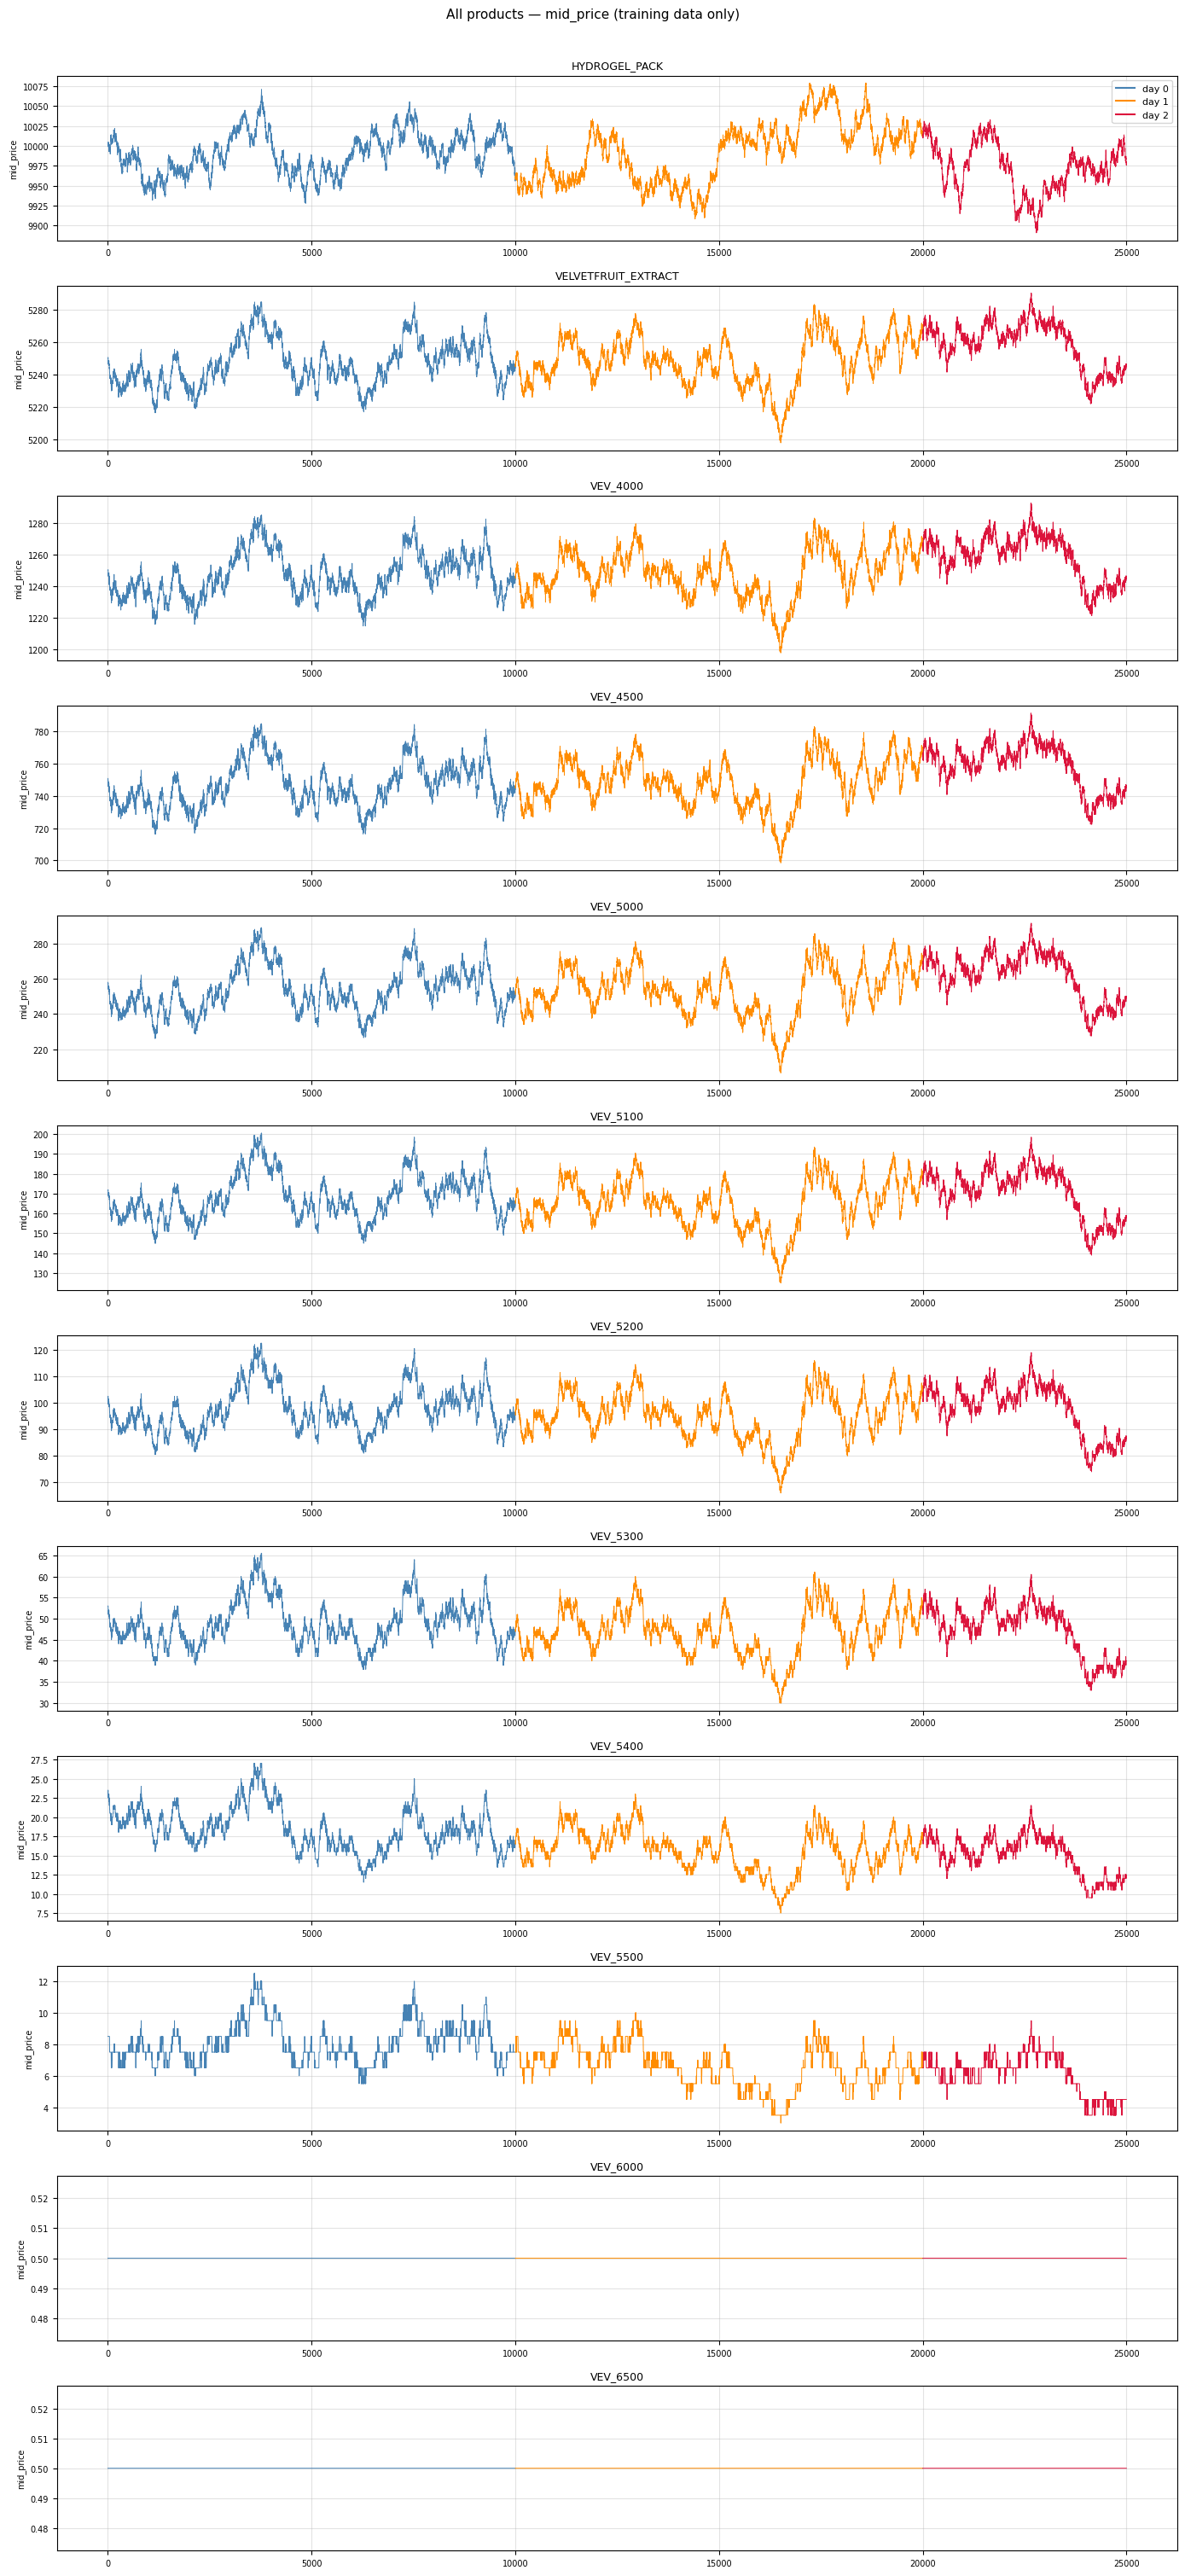

In [16]:
all_products = sorted(prices['product'].unique())
n = len(all_products)
fig, axes = plt.subplots(n, 1, figsize=(14, 2.5*n), sharex=False)
for i, prod in enumerate(all_products):
    p = prices[prices['product'] == prod]
    for day in train_days:
        seg = p[p['day'] == day]
        axes[i].plot(seg['gx'], seg['mid_price'],
                     color=DAY_COLORS[day], linewidth=0.7, label=f"day {day}")
    axes[i].set_title(prod, fontsize=9)
    axes[i].set_ylabel("mid_price", fontsize=7)
    axes[i].tick_params(labelsize=7)
handles = [plt.Line2D([0],[0], color=DAY_COLORS[d], label=f"day {d}") for d in train_days]
axes[0].legend(handles=handles, fontsize=8, loc='upper right')
plt.suptitle("All products — mid_price (training data only)", y=1.005, fontsize=11)
plt.tight_layout(); plt.show()


In [6]:
rows = []
for prod in all_products:
    p = prices[prices['product'] == prod]['mid_price']
    rows.append({'product': prod, 'mean': p.mean(), 'std': p.std(),
                 'min': p.min(), 'max': p.max()})
print(pd.DataFrame(rows).to_string(index=False, float_format=lambda x: f'{x:.2f}'))


            product    mean   std     min      max
      HYDROGEL_PACK 9987.46 32.84 9891.00 10079.00
VELVETFRUIT_EXTRACT 5249.77 14.85 5198.00  5290.00
           VEV_4000 1249.79 14.86 1198.00  1292.50
           VEV_4500  749.79 14.86  698.50   791.50
           VEV_5000  255.06 13.54  206.50   291.50
           VEV_5100  167.46 11.84  125.00   200.50
           VEV_5200   96.64  8.73   66.00   122.50
           VEV_5300   47.80  5.52   30.00    65.50
           VEV_5400   16.65  3.08    7.50    27.00
           VEV_5500    7.07  1.52    3.00    12.50
           VEV_6000    0.50  0.00    0.50     0.50
           VEV_6500    0.50  0.00    0.50     0.50


## 2. VELVETFRUIT_EXTRACT (Underlying)

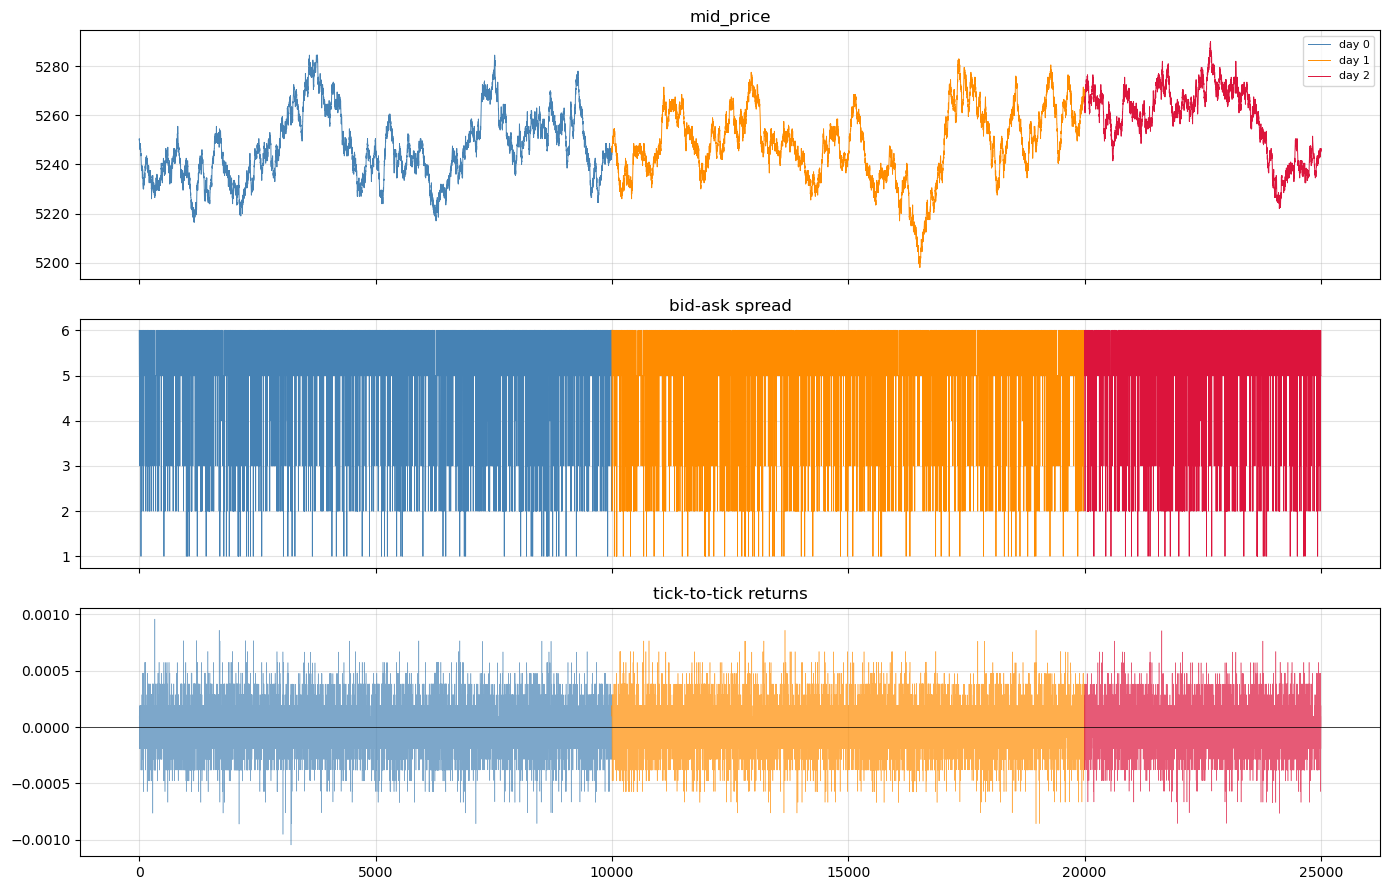

In [7]:
vev = prices[prices['product'] == UNDERLYING].copy()
vev['spread'] = vev['ask_price_1'] - vev['bid_price_1']
vev['ret']    = vev['mid_price'].diff() / vev['mid_price'].shift(1)

# Compute mean per day + overall mean
overall_mean = vev['mid_price'].mean()
daily_means = vev.groupby('day')['mid_price'].mean()

fig, axes = plt.subplots(3, 1, figsize=(14, 9), sharex=True)
for day in train_days:
    seg = vev[vev['day'] == day]
    axes[0].plot(seg['gx'], seg['mid_price'], color=DAY_COLORS[day], linewidth=0.7, label=f"day {day}")
    # Add per-day mean line
    axes[0].axhline(daily_means[day], color=DAY_COLORS[day], linestyle='--', linewidth=1.2, alpha=0.6)
    axes[1].plot(seg['gx'], seg['spread'],    color=DAY_COLORS[day], linewidth=0.6)
    axes[2].plot(seg['gx'], seg['ret'],       color=DAY_COLORS[day], linewidth=0.4, alpha=0.7)

# Add overall mean
axes[0].axhline(overall_mean, color='black', linestyle='-', linewidth=1.5, label=f"overall mean = {overall_mean:.1f}", alpha=0.7)

axes[0].set_title("mid_price with mean lines"); axes[0].legend(fontsize=8)
axes[1].set_title("bid-ask spread")
axes[2].set_title("tick-to-tick returns"); axes[2].axhline(0, color='black', linewidth=0.5)
plt.tight_layout(); plt.show()

# Print stats for reference
print("\nVELVETFRUIT_EXTRACT mean reversion stats:")
print(f"  Overall mean: {overall_mean:.2f}")
for day in train_days:
    print(f"  Day {day} mean: {daily_means[day]:.2f}")

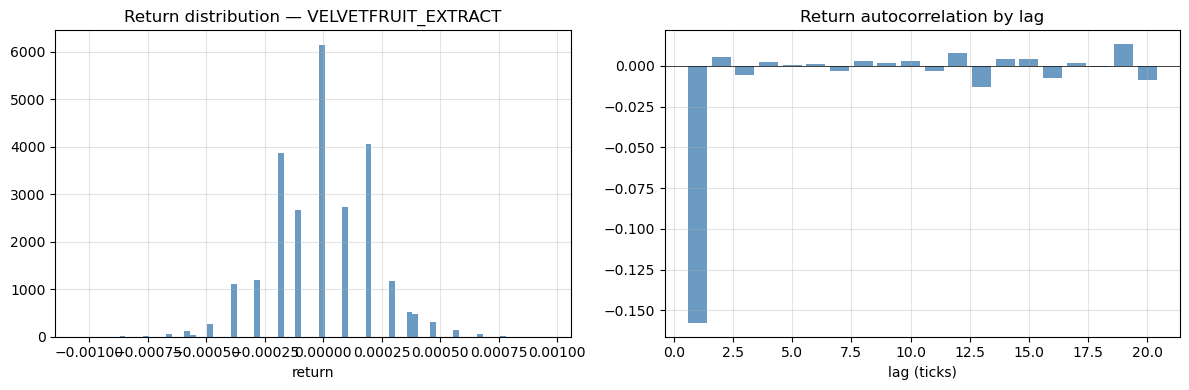

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
ret = vev['ret'].dropna()
axes[0].hist(ret, bins=80, color='steelblue', edgecolor='none', alpha=0.8)
axes[0].set_title("Return distribution — VELVETFRUIT_EXTRACT")
axes[0].set_xlabel("return")

lags = range(1, 21)
acf  = [ret.autocorr(l) for l in lags]
axes[1].bar(list(lags), acf, color='steelblue', alpha=0.8)
axes[1].axhline(0, color='black', linewidth=0.5)
axes[1].set_title("Return autocorrelation by lag")
axes[1].set_xlabel("lag (ticks)")
plt.tight_layout(); plt.show()


## 3. HYDROGEL_PACK

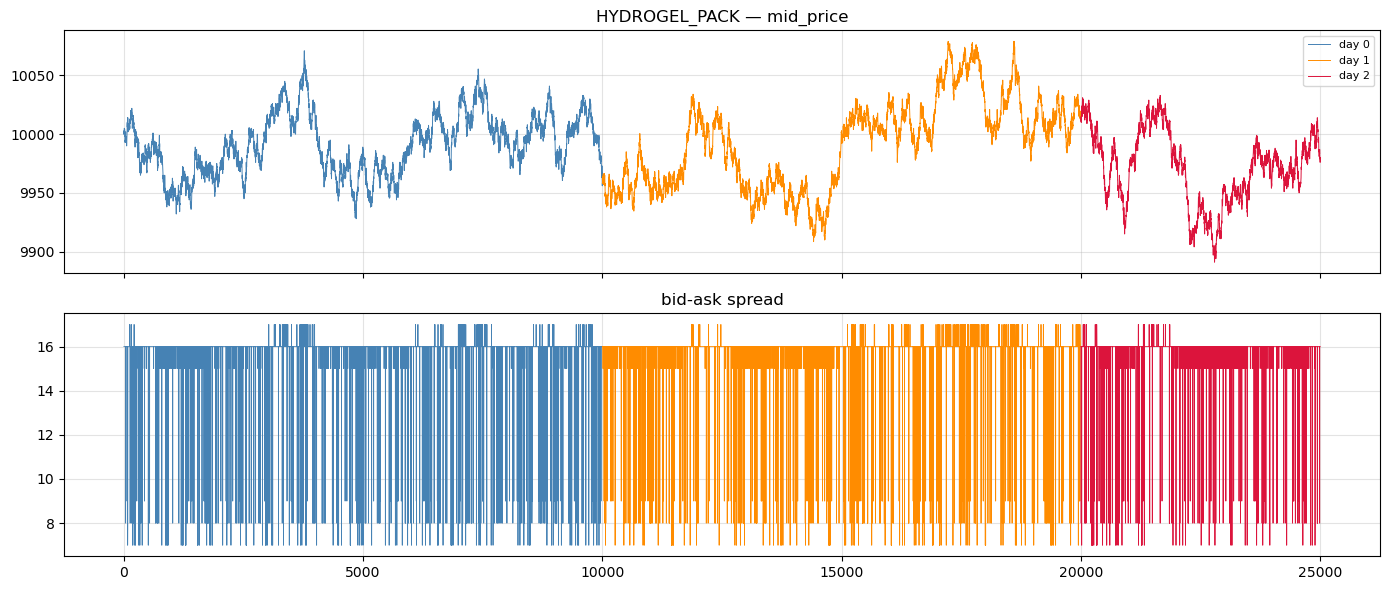

In [9]:
hydr = prices[prices['product'] == HYDROGEL].copy()
hydr['spread'] = hydr['ask_price_1'] - hydr['bid_price_1']

# Compute mean per day + overall mean
overall_mean = hydr['mid_price'].mean()
daily_means = hydr.groupby('day')['mid_price'].mean()

fig, axes = plt.subplots(2, 1, figsize=(14, 6), sharex=True)
for day in train_days:
    seg = hydr[hydr['day'] == day]
    axes[0].plot(seg['gx'], seg['mid_price'], color=DAY_COLORS[day], linewidth=0.7, label=f"day {day}")
    # Add per-day mean line
    axes[0].axhline(daily_means[day], color=DAY_COLORS[day], linestyle='--', linewidth=1.2, alpha=0.6)
    axes[1].plot(seg['gx'], seg['spread'],    color=DAY_COLORS[day], linewidth=0.6)

# Add overall mean
axes[0].axhline(overall_mean, color='black', linestyle='-', linewidth=1.5, label=f"overall mean = {overall_mean:.1f}", alpha=0.7)

axes[0].set_title("HYDROGEL_PACK — mid_price with mean lines"); axes[0].legend(fontsize=8, loc='upper right')
axes[1].set_title("bid-ask spread")
plt.tight_layout(); plt.show()

# Print stats for reference
print("\nHYDROGEL_PACK mean reversion stats:")
print(f"  Overall mean: {overall_mean:.2f}")
for day in train_days:
    print(f"  Day {day} mean: {daily_means[day]:.2f}")

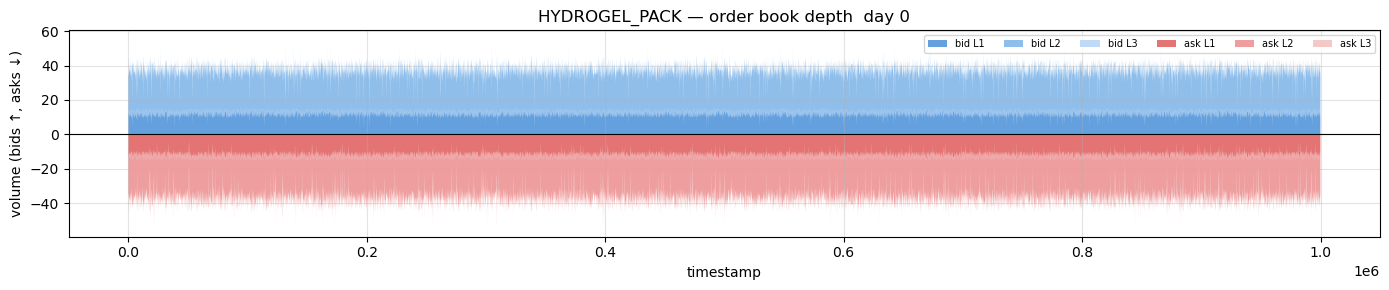

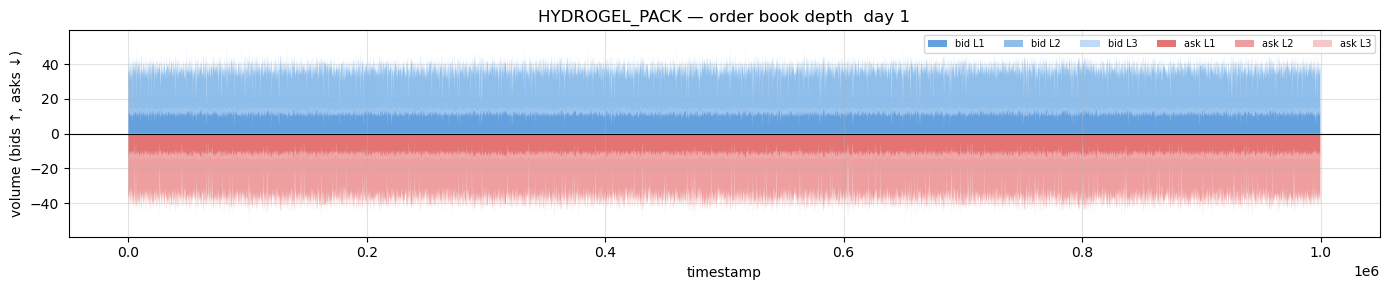

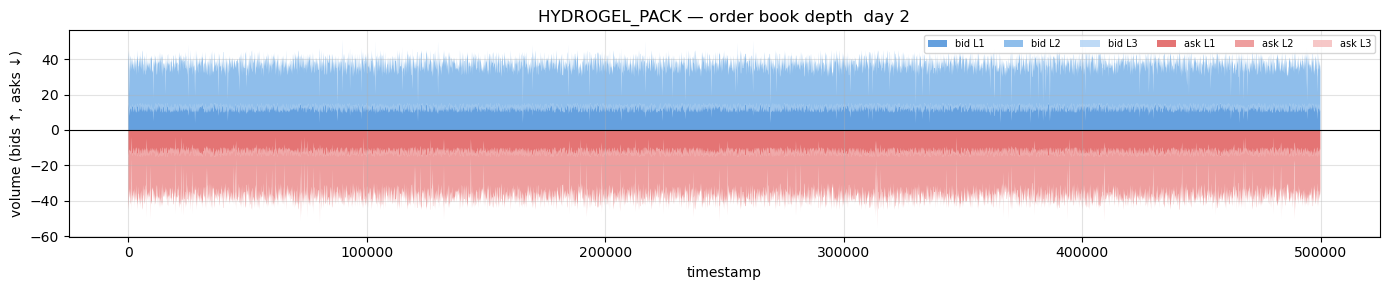

In [10]:
for day in train_days:
    ph = hydr[hydr['day'] == day].sort_values('timestamp')
    for c in ['bid_volume_1','bid_volume_2','bid_volume_3',
              'ask_volume_1','ask_volume_2','ask_volume_3']:
        ph[c] = ph[c].fillna(0)
    ts = ph['timestamp'].values
    fig, ax = plt.subplots(figsize=(14, 3))
    ax.stackplot(ts,
                  ph['bid_volume_1'], ph['bid_volume_2'], ph['bid_volume_3'],
                  colors=['#4a90d9','#7bb3e8','#b3d4f5'], alpha=0.85,
                  labels=['bid L1','bid L2','bid L3'])
    ax.stackplot(ts,
                 -ph['ask_volume_1'], -ph['ask_volume_2'], -ph['ask_volume_3'],
                 colors=['#e05c5c','#ec8d8d','#f5bebe'], alpha=0.85,
                 labels=['ask L1','ask L2','ask L3'])
    ax.axhline(0, color='black', linewidth=0.8)
    ax.set_title(f"HYDROGEL_PACK — order book depth  day {day}")
    ax.set_ylabel("volume (bids ↑, asks ↓)"); ax.set_xlabel("timestamp")
    ax.legend(fontsize=7, ncol=6, loc='upper right')
    plt.tight_layout(); plt.show()


## 4. Options Chain — Raw Prices

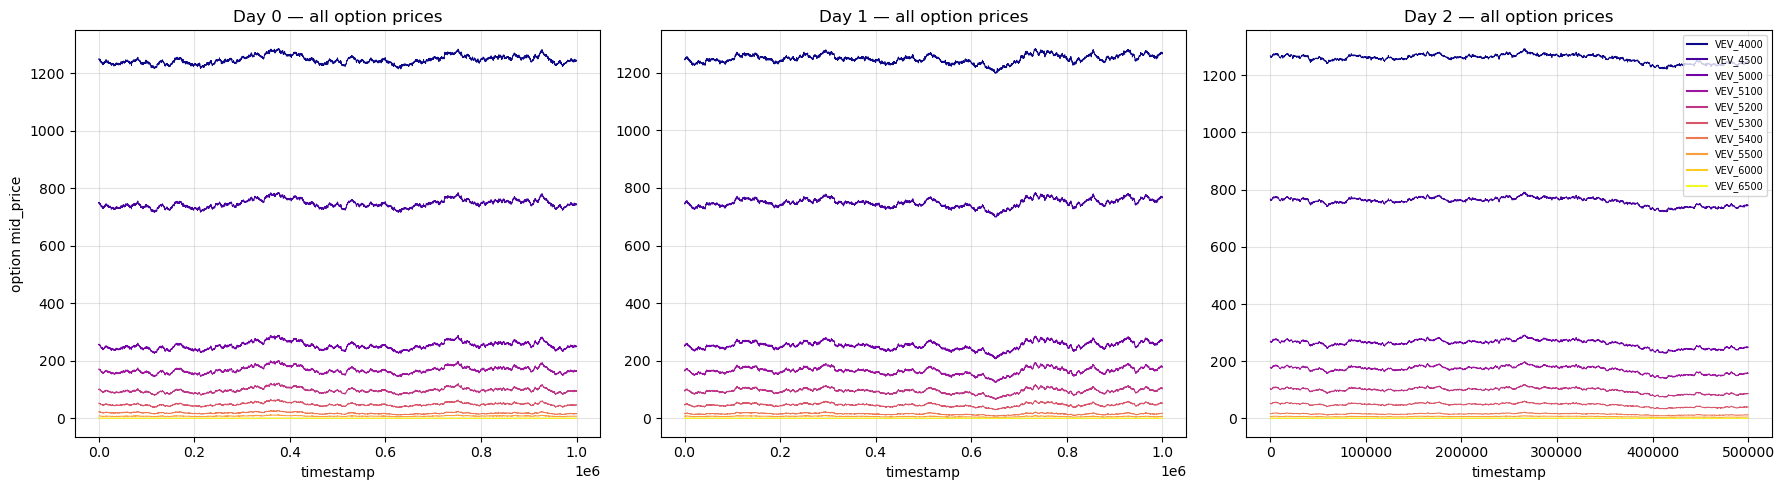

In [11]:
cmap     = plt.cm.plasma
colors_k = {k: cmap(i / (len(STRIKES)-1)) for i, k in enumerate(STRIKES)}

fig, axes = plt.subplots(1, len(train_days), figsize=(6*len(train_days), 5))
if len(train_days) == 1: axes = [axes]
for di, day in enumerate(train_days):
    for k in STRIKES:
        seg = prices[(prices['product'] == f'VEV_{k}') & (prices['day'] == day)]
        axes[di].plot(seg['timestamp'], seg['mid_price'],
                      color=colors_k[k], linewidth=0.7)
    axes[di].set_title(f"Day {day} — all option prices")
    axes[di].set_xlabel("timestamp")
    axes[di].set_ylabel("option mid_price") if di == 0 else None
handles = [plt.Line2D([0],[0], color=colors_k[k], label=f'VEV_{k}') for k in STRIKES]
axes[-1].legend(handles=handles, fontsize=7, loc='upper right')
plt.tight_layout(); plt.show()


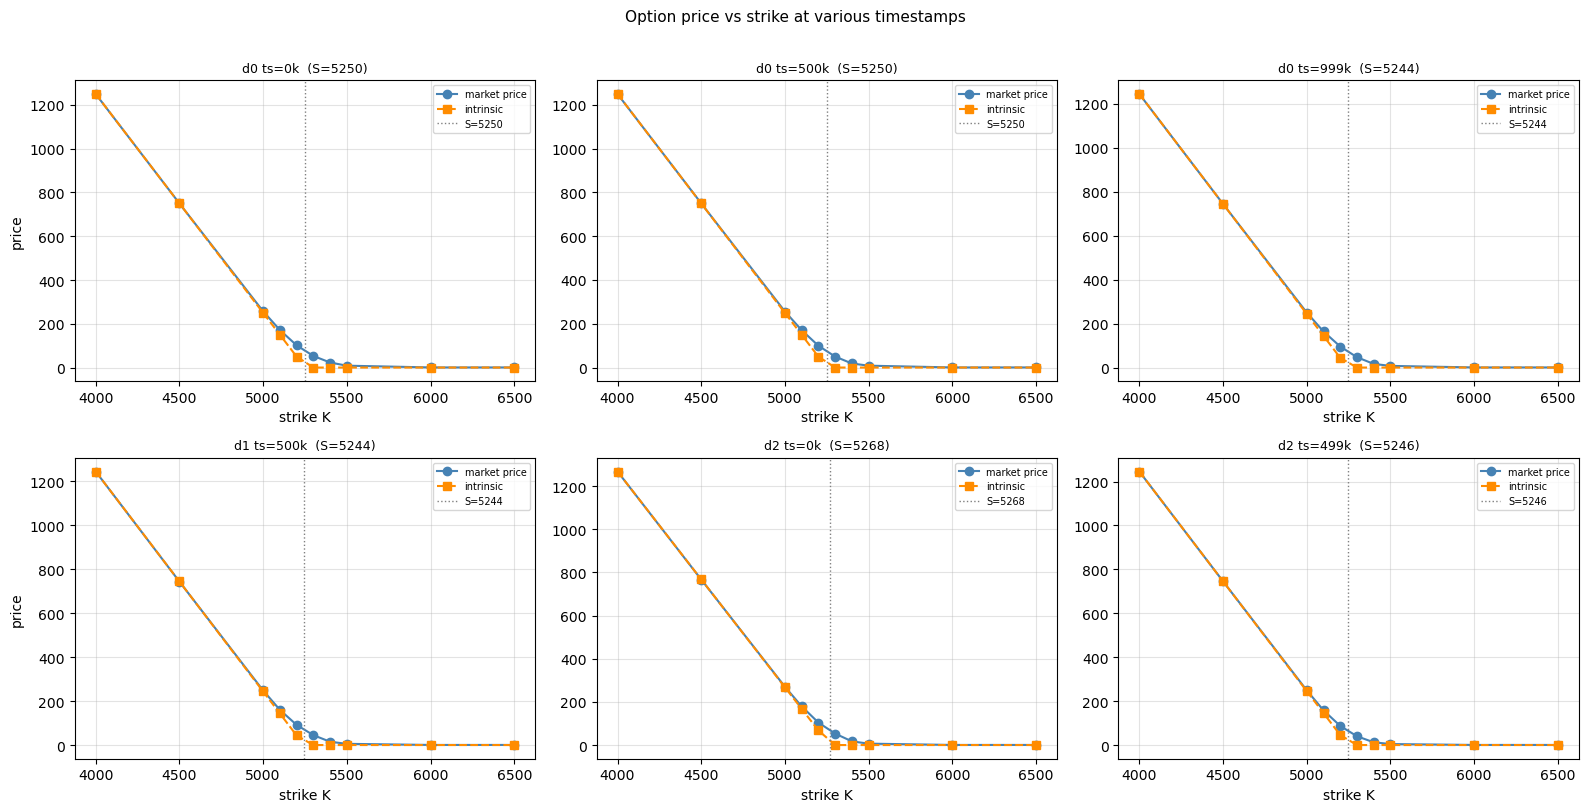

In [12]:
# Option price vs strike at several snapshots — all within training window
snapshots = [(0, 0), (0, 500000), (0, 999900),
             (1, 500000), (2, 0), (2, 499900)]

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
axes = axes.flatten()
for si, (day, ts) in enumerate(snapshots):
    S_row = prices[(prices['product'] == UNDERLYING) &
                   (prices['day'] == day) &
                   (prices['timestamp'] == ts)]['mid_price'].values
    if not len(S_row): axes[si].set_title(f"d{day} ts{ts} — no data"); continue
    S = S_row[0]
    Ks, Cs = [], []
    for k in STRIKES:
        row = prices[(prices['product'] == f'VEV_{k}') &
                     (prices['day'] == day) &
                     (prices['timestamp'] == ts)]['mid_price'].values
        if len(row): Ks.append(k); Cs.append(row[0])
    intrinsics = [max(S - k, 0) for k in Ks]
    axes[si].plot(Ks, Cs,         'o-', color='steelblue',  label='market price')
    axes[si].plot(Ks, intrinsics, 's--', color='darkorange', label='intrinsic')
    axes[si].axvline(S, color='gray', linestyle=':', linewidth=1, label=f'S={S:.0f}')
    axes[si].set_title(f"d{day} ts={ts//1000}k  (S={S:.0f})", fontsize=9)
    axes[si].set_xlabel("strike K"); axes[si].set_ylabel("price") if si % 3 == 0 else None
    axes[si].legend(fontsize=7)
plt.suptitle("Option price vs strike at various timestamps", fontsize=11, y=1.01)
plt.tight_layout(); plt.show()


## 5. Intrinsic Value & Time Value

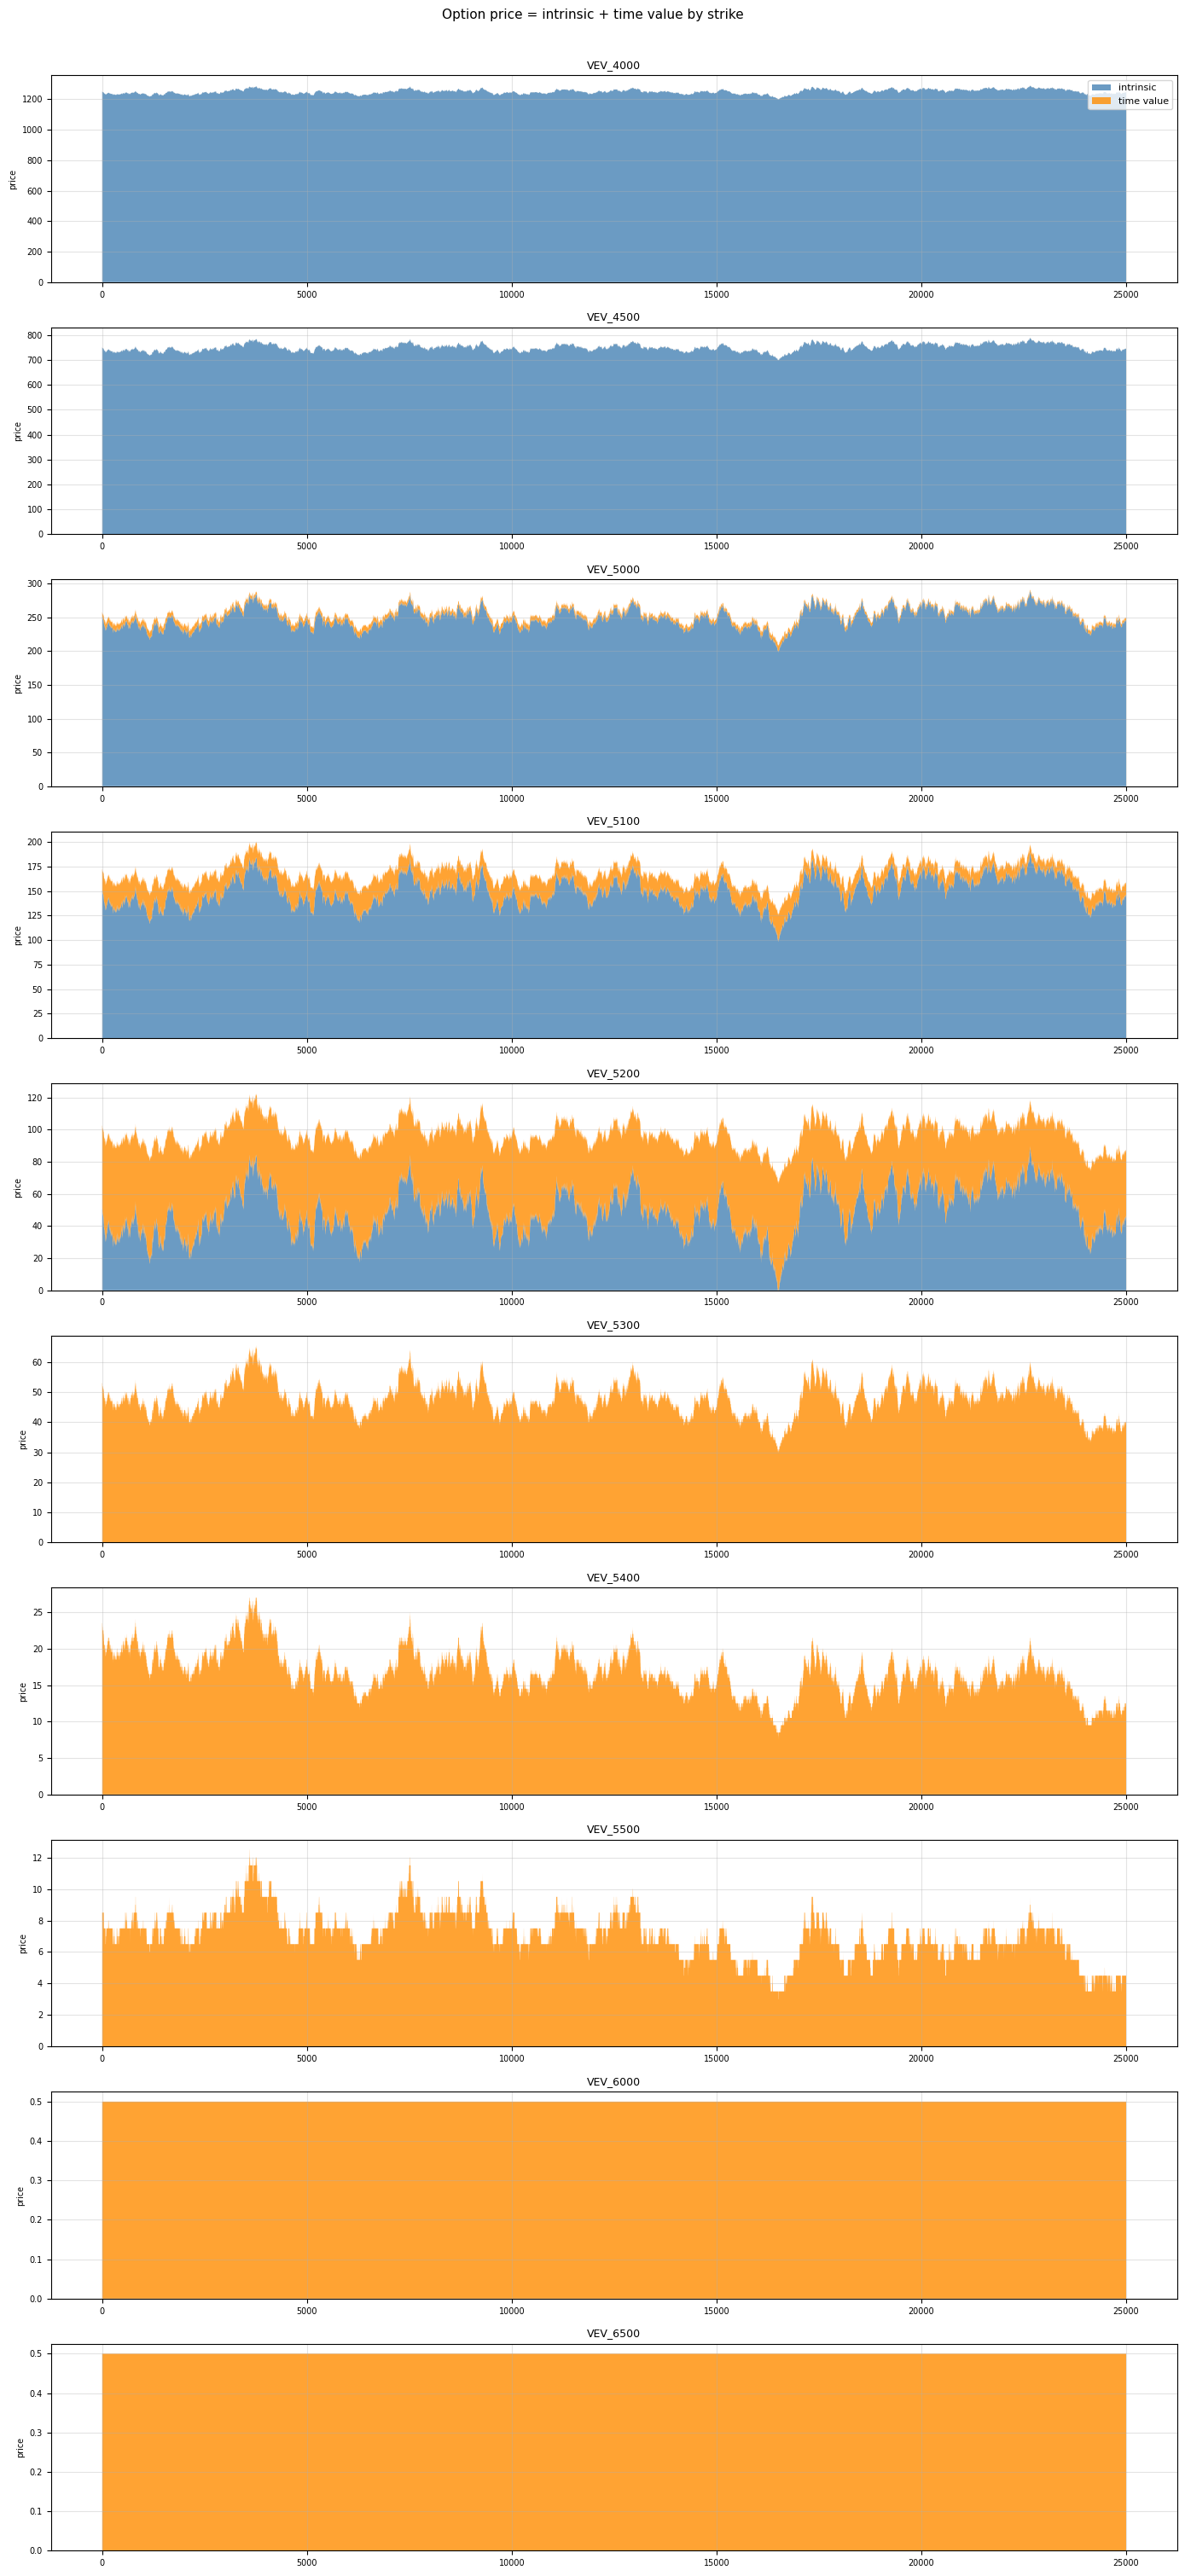

In [13]:
fig, axes = plt.subplots(len(STRIKES), 1, figsize=(14, 3*len(STRIKES)), sharex=False)
for i, k in enumerate(STRIKES):
    opt = prices[prices['product'] == f'VEV_{k}'].set_index(['day','timestamp'])['mid_price']
    df  = pd.DataFrame({'C': opt, 'S': S_idx}).dropna()
    df['intrinsic'] = (df['S'] - k).clip(lower=0)
    df['time_val']  = df['C'] - df['intrinsic']
    df = df.reset_index(); df['gx'] = range(len(df))
    axes[i].stackplot(df['gx'], df['intrinsic'], df['time_val'],
                      labels=['intrinsic','time value'],
                      colors=['steelblue','darkorange'], alpha=0.8)
    axes[i].set_title(f"VEV_{k}", fontsize=9)
    axes[i].set_ylabel("price", fontsize=7)
    axes[i].tick_params(labelsize=7)
    if i == 0: axes[i].legend(fontsize=8, loc='upper right')
plt.suptitle("Option price = intrinsic + time value by strike", y=1.005, fontsize=11)
plt.tight_layout(); plt.show()


In [ ]:
# Time value per strike per day — only training days
liquid = [k for k in STRIKES if k not in (4000, 4500, 6000, 6500)]
fig, ax = plt.subplots(figsize=(12, 5))
x     = np.arange(len(liquid))
width = 0.28
for di, day in enumerate(train_days):
    tv_vals = []
    for k in liquid:
        c_mean = prices[(prices['product']==f'VEV_{k}') & (prices['day']==day)]['mid_price'].mean()
        s_mean = prices[(prices['product']==UNDERLYING)  & (prices['day']==day)]['mid_price'].mean()
        tv_vals.append(max(c_mean - max(s_mean - k, 0), 0))
    ax.bar(x + di*width, tv_vals, width, label=f"day {day}",
           color=list(DAY_COLORS.values())[di], alpha=0.8)
ax.set_xticks(x + width); ax.set_xticklabels([f'VEV_{k}' for k in liquid])
ax.set_ylabel("avg time value"); ax.set_title("Time value per strike per training day")
ax.legend(); plt.tight_layout(); plt.show()


## 6. Option Price vs Underlying Price

In [ ]:
liquid = [k for k in STRIKES if k not in (6000, 6500)]
n_cols = 3; n_rows = math.ceil(len(liquid) / n_cols)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, 4*n_rows))
axes = axes.flatten()
for i, k in enumerate(liquid):
    opt = prices[prices['product'] == f'VEV_{k}'].set_index(['day','timestamp'])['mid_price']
    df  = pd.DataFrame({'C': opt, 'S': S_idx}).dropna()
    for day in train_days:
        mask = df.index.get_level_values('day') == day
        axes[i].scatter(df['S'][mask], df['C'][mask],
                        s=1, alpha=0.3, color=DAY_COLORS[day])
    s_range = np.linspace(df['S'].min(), df['S'].max(), 200)
    axes[i].plot(s_range, np.maximum(s_range - k, 0),
                 color='black', linewidth=1, linestyle='--', label='intrinsic')
    axes[i].set_title(f"VEV_{k}", fontsize=9)
    axes[i].set_xlabel("S", fontsize=7); axes[i].set_ylabel("C", fontsize=7)
    axes[i].legend(fontsize=7)
for j in range(i+1, len(axes)): axes[j].set_visible(False)
plt.suptitle("Option price vs underlying — scatter by day (dashed = intrinsic)", y=1.01, fontsize=11)
plt.tight_layout(); plt.show()


In [ ]:
fig, ax = plt.subplots(figsize=(14, 5))
for k in liquid:
    opt = prices[prices['product'] == f'VEV_{k}'].set_index(['day','timestamp'])['mid_price']
    df  = pd.DataFrame({'C': opt, 'S': S_idx}).dropna().reset_index()
    dC  = df['C'].diff(); dS = df['S'].diff()
    ratio    = (dC / dS).replace([np.inf, -np.inf], np.nan)
    smoothed = ratio.rolling(200, min_periods=20).median()
    df['gx'] = range(len(df))
    ax.plot(df['gx'], smoothed, linewidth=0.8, label=f'VEV_{k}')
ax.axhline(0, color='black', linewidth=0.5)
ax.axhline(1, color='gray',  linewidth=0.5, linestyle='--')
ax.set_ylim(-0.2, 1.3)
ax.set_title("Empirical delta — rolling 200-tick median of dC/dS per strike")
ax.set_xlabel("tick"); ax.set_ylabel("dC/dS")
ax.legend(fontsize=8, ncol=3); plt.tight_layout(); plt.show()


## 7. Return Correlations — All Products

In [ ]:
wide     = prices.pivot_table(index=['day','timestamp'], columns='product', values='mid_price')
ret_wide = wide.pct_change().dropna()
corr     = ret_wide.corr()
n = len(corr)
fig, ax = plt.subplots(figsize=(max(8, n*0.9), max(7, n*0.8)))
im = ax.imshow(corr, cmap='RdYlGn', vmin=-1, vmax=1)
ax.set_xticks(range(n)); ax.set_xticklabels(corr.columns, rotation=45, ha='right', fontsize=8)
ax.set_yticks(range(n)); ax.set_yticklabels(corr.columns, fontsize=8)
for i in range(n):
    for j in range(n):
        ax.text(j, i, f"{corr.iloc[i,j]:.2f}", ha='center', va='center', fontsize=6)
plt.colorbar(im, ax=ax)
ax.set_title("Return correlation matrix")
plt.tight_layout(); plt.show()


## 8. Implied Volatility

IV is computed by numerically inverting Black-Scholes: find σ such that BS(S, K, T=1.0, σ) = market price.
Raw values only — no smoothing, no signals.


In [ ]:
def norm_cdf(x):
    a1,a2,a3,a4,a5 = 0.254829592,-0.284496736,1.421413741,-1.453152027,1.061405429
    p = 0.3275911; sign = 1 if x >= 0 else -1
    x = abs(x) / math.sqrt(2.0); t = 1.0 / (1.0 + p*x)
    y = 1.0 - (((((a5*t+a4)*t)+a3)*t+a2)*t+a1)*t*math.exp(-x*x)
    return 0.5*(1.0 + sign*y)

def bs_call(S, K, T, sigma):
    if T <= 0 or sigma <= 0: return max(S - K, 0.0)
    d1 = (math.log(S/K) + 0.5*sigma**2*T) / (sigma*math.sqrt(T))
    d2 = d1 - sigma*math.sqrt(T)
    return S*norm_cdf(d1) - K*norm_cdf(d2)

def implied_vol(mkt, S, K, T=1.0):
    if mkt <= max(S - K, 0.0) or S <= 0: return np.nan
    lo, hi = 1e-6, 5.0
    if bs_call(S, K, T, hi) < mkt: return np.nan
    for _ in range(100):
        mid = (lo + hi) / 2
        if bs_call(S, K, T, mid) < mkt: lo = mid
        else: hi = mid
        if hi - lo < 1e-6: return (lo + hi) / 2
    return (lo + hi) / 2

T_REF     = 1.0
iv_liquid = [k for k in STRIKES if k not in (4000, 4500, 6000, 6500)]
colors_iv = plt.cm.plasma(np.linspace(0.1, 0.9, len(iv_liquid)))


In [ ]:
iv_data = {}
for k in iv_liquid:
    opt = prices[prices['product'] == f'VEV_{k}'].copy()              .sort_values(['day','timestamp']).reset_index(drop=True)
    opt = opt.join(S_idx.rename('S'), on=['day','timestamp'])
    opt['IV'] = [implied_vol(r['mid_price'], r['S'], k)
                 for _, r in opt.iterrows()]
    opt['gx'] = range(len(opt))
    iv_data[k] = opt

fig, ax = plt.subplots(figsize=(14, 5))
for i, k in enumerate(iv_liquid):
    df = iv_data[k]
    ax.plot(df['gx'], df['IV'], linewidth=0.6, color=colors_iv[i], label=f'VEV_{k}')
ax.set_title(f"Implied volatility per strike  (T={T_REF})")
ax.set_xlabel("tick"); ax.set_ylabel("IV")
ax.legend(fontsize=8, ncol=3); plt.tight_layout(); plt.show()


In [ ]:
# IV box plots per strike per day
fig, ax = plt.subplots(figsize=(14, 5))
box_data, positions = [], []
for ki, k in enumerate(iv_liquid):
    for di, day in enumerate(train_days):
        iv_vals = iv_data[k][iv_data[k]['day'] == day]['IV'].dropna().values
        box_data.append(iv_vals)
        positions.append(ki * (len(train_days) + 1) + di)

bp = ax.boxplot(box_data, positions=positions, widths=0.6, patch_artist=True,
                medianprops=dict(color='black', linewidth=1.5))
for i, patch in enumerate(bp['boxes']):
    patch.set_facecolor(list(DAY_COLORS.values())[i % len(train_days)])
    patch.set_alpha(0.7)
tick_pos = [ki*(len(train_days)+1) + (len(train_days)-1)/2 for ki in range(len(iv_liquid))]
ax.set_xticks(tick_pos); ax.set_xticklabels([f'VEV_{k}' for k in iv_liquid])
ax.set_title("IV distribution per strike per day"); ax.set_ylabel("IV")
handles = [plt.Rectangle((0,0),1,1, color=list(DAY_COLORS.values())[d], alpha=0.7)
           for d in range(len(train_days))]
ax.legend(handles, [f'day {d}' for d in train_days], fontsize=8)
plt.tight_layout(); plt.show()


In [ ]:
# Vol smile — all snapshots within training window
snapshots = [(0, 0), (0, 500000), (0, 999900),
             (1, 500000), (2, 0), (2, 499900)]

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
axes = axes.flatten()
for si, (day, ts) in enumerate(snapshots):
    S_arr = prices[(prices['product']==UNDERLYING) &
                   (prices['day']==day) &
                   (prices['timestamp']==ts)]['mid_price'].values
    if not len(S_arr): axes[si].set_title("no data"); continue
    S = S_arr[0]
    mn_vals, iv_vals, k_vals = [], [], []
    for k in iv_liquid:
        c_arr = prices[(prices['product']==f'VEV_{k}') &
                       (prices['day']==day) &
                       (prices['timestamp']==ts)]['mid_price'].values
        if len(c_arr):
            v = implied_vol(c_arr[0], S, k)
            if not np.isnan(v):
                mn_vals.append(S/k); iv_vals.append(v); k_vals.append(k)
    if mn_vals:
        axes[si].plot(mn_vals, iv_vals, 'o-', color='teal', linewidth=1.2, markersize=6)
        for kk, mn, iv_v in zip(k_vals, mn_vals, iv_vals):
            axes[si].annotate(str(kk), (mn, iv_v),
                              textcoords='offset points', xytext=(0,6), fontsize=7, ha='center')
    axes[si].axvline(1.0, color='gray', linestyle='--', linewidth=0.8)
    axes[si].set_title(f"d{day} ts={ts//1000}k  (S={S:.0f})", fontsize=9)
    axes[si].set_xlabel("moneyness S/K")
    axes[si].set_ylabel("IV") if si % 3 == 0 else None
plt.suptitle("Volatility smile at various timestamps", fontsize=11, y=1.01)
plt.tight_layout(); plt.show()


In [ ]:
# IV heatmap — strike (y) vs tick (x)
from matplotlib.colors import Normalize
step     = 50
n_ticks  = len(iv_data[iv_liquid[0]])
tick_idx = list(range(0, n_ticks, step))
surface  = np.full((len(iv_liquid), len(tick_idx)), np.nan)
for ri, k in enumerate(iv_liquid):
    iv_arr = iv_data[k]['IV'].values
    for ci, ti in enumerate(tick_idx):
        if ti < len(iv_arr): surface[ri, ci] = iv_arr[ti]

fig, ax = plt.subplots(figsize=(16, 5))
im = ax.imshow(surface, aspect='auto', cmap='RdYlGn_r',
               norm=Normalize(vmin=np.nanpercentile(surface, 2),
                              vmax=np.nanpercentile(surface, 98)))
ax.set_yticks(range(len(iv_liquid)))
ax.set_yticklabels([f'VEV_{k}' for k in iv_liquid], fontsize=8)
n_xt = 20
xtick_pos  = [int(i * len(tick_idx) / n_xt) for i in range(n_xt)]
xtick_labs = []
for tp in xtick_pos:
    ti  = tick_idx[min(tp, len(tick_idx)-1)]
    row = iv_data[iv_liquid[0]].iloc[min(ti, n_ticks-1)]
    xtick_labs.append(f"d{int(row['day'])}/{int(row['timestamp'])//1000}k")
ax.set_xticks(xtick_pos)
ax.set_xticklabels(xtick_labs, rotation=45, ha='right', fontsize=7)
plt.colorbar(im, ax=ax, label="IV")
ax.set_title("IV heatmap — strike vs time")
plt.tight_layout(); plt.show()


## 9. Greeks (Delta, Gamma, Theta)

In [ ]:
def bs_delta(S, K, T, sigma):
    if T <= 0 or sigma <= 0: return 1.0 if S > K else 0.0
    d1 = (math.log(S/K) + 0.5*sigma**2*T) / (sigma*math.sqrt(T))
    return norm_cdf(d1)

def bs_gamma(S, K, T, sigma):
    if T <= 0 or sigma <= 0: return 0.0
    d1 = (math.log(S/K) + 0.5*sigma**2*T) / (sigma*math.sqrt(T))
    return math.exp(-0.5*d1**2) / (S * sigma * math.sqrt(T) * math.sqrt(2*math.pi))

def bs_theta(S, K, T, sigma):
    if T <= 0 or sigma <= 0: return 0.0
    d1 = (math.log(S/K) + 0.5*sigma**2*T) / (sigma*math.sqrt(T))
    return -(S * math.exp(-0.5*d1**2) * sigma) / (2*math.sqrt(T)*math.sqrt(2*math.pi)) / 365


In [ ]:
fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=False)
for i, k in enumerate(iv_liquid):
    df      = iv_data[k].copy()
    df      = df.join(S_idx.rename('S'), on=['day','timestamp'])
    mean_iv = df['IV'].mean()
    df['iv_use'] = df['IV'].fillna(mean_iv)
    df['delta']  = [bs_delta(r['S'], k, T_REF, r['iv_use']) if pd.notna(r['S']) else np.nan for _, r in df.iterrows()]
    df['gamma']  = [bs_gamma(r['S'], k, T_REF, r['iv_use']) if pd.notna(r['S']) else np.nan for _, r in df.iterrows()]
    df['theta']  = [bs_theta(r['S'], k, T_REF, r['iv_use']) if pd.notna(r['S']) else np.nan for _, r in df.iterrows()]
    col = colors_iv[i]
    axes[0].plot(df['gx'], df['delta'], linewidth=0.6, color=col, label=f'VEV_{k}')
    axes[1].plot(df['gx'], df['gamma'], linewidth=0.6, color=col)
    axes[2].plot(df['gx'], df['theta'], linewidth=0.6, color=col)
axes[0].set_ylabel("delta"); axes[0].legend(fontsize=7, ncol=3)
axes[0].set_title("Delta, Gamma, Theta per strike — training ticks")
axes[1].set_ylabel("gamma")
axes[2].set_ylabel("theta (per year)"); axes[2].set_xlabel("tick")
plt.tight_layout(); plt.show()


In [ ]:
S_mean  = prices[prices['product']==UNDERLYING]['mid_price'].mean()
iv_flat = np.mean([iv_data[k]['IV'].mean() for k in iv_liquid])
K_range = np.linspace(4800, 5700, 300)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
axes[0].plot(K_range, [bs_delta(S_mean, k, T_REF, iv_flat) for k in K_range], linewidth=1.5, color='steelblue')
axes[1].plot(K_range, [bs_gamma(S_mean, k, T_REF, iv_flat) for k in K_range], linewidth=1.5, color='darkorange')
axes[2].plot(K_range, [bs_theta(S_mean, k, T_REF, iv_flat) for k in K_range], linewidth=1.5, color='crimson')
for ax, title, ylabel in zip(axes,
        ['Delta vs Strike', 'Gamma vs Strike', 'Theta vs Strike'],
        ['delta', 'gamma', 'theta/year']):
    ax.axvline(S_mean, color='gray', linestyle='--', linewidth=1, label=f'S={S_mean:.0f}')
    ax.set_title(f"{title}  (σ={iv_flat:.4f}, T={T_REF})"); ax.set_xlabel("K")
    ax.set_ylabel(ylabel); ax.legend(fontsize=8)
    for k in iv_liquid: ax.axvline(k, color='lightgray', linewidth=0.5)
plt.tight_layout(); plt.show()


## 10. Trade Activity

In [ ]:
vol_summary = (trades.groupby('symbol')['quantity']
               .agg(n_trades='count', total_vol='sum')
               .sort_values('total_vol', ascending=False))
print(vol_summary.to_string())


In [ ]:
for prod in [UNDERLYING, HYDROGEL] + [f'VEV_{k}' for k in [5200, 5300, 5400]]:
    p = prices[prices['product'] == prod].copy()
    p['x'] = p['day'] * 1_100_000 + p['timestamp']
    t = trades[trades['symbol'] == prod].copy()
    t['x'] = t['day'] * 1_100_000 + t['timestamp']
    if t.empty: continue
    fig, ax = plt.subplots(figsize=(14, 4))
    ax.plot(p['x'], p['mid_price'], color='black', linewidth=0.5, alpha=0.4, label='mid_price')
    ax.scatter(t['x'], t['price'], s=15, color='crimson', zorder=3, alpha=0.7, label='trades')
    for day in train_days:
        ax.axvline(day * 1_100_000, color='gray', linestyle='--', linewidth=0.5, alpha=0.4)
    ax.set_title(f"{prod} — trade prices vs mid_price")
    ax.set_xlabel("day × 1.1M + timestamp"); ax.set_ylabel("price")
    ax.legend(fontsize=8); plt.tight_layout(); plt.show()


In [ ]:
trade_prods = sorted(trades['symbol'].unique())
n = len(trade_prods)
fig, axes = plt.subplots(math.ceil(n/3), 3, figsize=(16, 4*math.ceil(n/3)))
axes = axes.flatten()
for i, prod in enumerate(trade_prods):
    t = trades[trades['symbol'] == prod]['quantity'].dropna()
    axes[i].hist(t, bins=30, color='steelblue', edgecolor='none', alpha=0.8)
    axes[i].set_title(prod, fontsize=9)
    axes[i].set_xlabel("quantity", fontsize=7)
for j in range(i+1, len(axes)): axes[j].set_visible(False)
plt.suptitle("Trade size distributions", fontsize=11, y=1.01)
plt.tight_layout(); plt.show()
